# Emotion Detection Data: Loading and Exploratory Data Analysis

**COS30082 Applied Machine Learning** · Swinburne University of Technology
**Group project:** Facial Recognition with Emotion and Liveness
**Notebook:** `backend_core/training/emotion_detection/emotion_detection_eda.ipynb`

---

# Introduction

## Course introduction

This notebook belongs to the group project of **COS30082 Applied Machine Learning**. The project builds a camera-based attendance system with three models:

| Model | Question it answers | Data |
|---|---|---|
| Face recognition (verification) | Who is this person? | `Face Recognition` data |
| Emotion recognition | How does the face look? | `Emotion Detection` data (**this notebook**) |
| Liveness (anti-spoofing) | Is this a real, live face? | `Anti-Spoofing` data |

The emotion model is a **multi-class image classifier**: it receives one face image and predicts one emotion out of seven. This notebook documents how the data is loaded and labelled and checks its quality before any model is trained.

**Group members:** Le Xuan Ny, Pahan Pathirathna, Nguyen Quang Khai, Pham Dinh Duc Anh, Pham Nguyen Minh Hoang, Truong Ngoc Gia Hieu.

## About this file

**Purpose.** Load the emotion dataset from Google Drive, assign a numeric label to every emotion, and audit the data so the team can decide the cleaning, splitting and class-weighting rules before training.

**What it does not do.** It trains no model and changes no data on Drive. Nothing here identifies a person.

**Questions the EDA answers**

1. How many images are there, and how many per emotion and per split?
2. Is the dataset balanced, or are some emotions rare?
3. What are the image sizes, formats and colour modes? Are any files corrupted, dark, blurry or low-contrast?
4. Does each emotion look different from the others (brightness, contrast, typical face)?
5. Are there duplicate images, images filed under two different emotions (label noise), or images shared between train and test (leakage)?
6. Is there a validation split? If not, how should one be created?

## How this notebook is organised

- **Every code cell does exactly one job** (one import block, one check, one `def`, one table, one chart). Its first line is a comment such as `# CELL 7: Configuration: outputs`. Comments inside the code explain each step.
- **Every code cell is followed by an explanation cell** with the same number: what the cell does, what goes in and out, what to check, and what to look at first if it fails.
- Cells depend on the ones above, so run them **from top to bottom**.
- All settings (paths, thresholds) are in the configuration cells near the top.

## Notebook structure

| Part | Section | Content |
|---|---|---|
| Introduction | Setup and configuration | Packages, libraries, Google Drive, settings, helper functions |
| **Part A** Data Loading and Assigning | 1.1 Locate the data | Find the dataset, check it exists, unzip if a zip is available |
| | 1.2 Load and label | List every image, assign an emotion label, save the inventory |
| **Part B** EDA | 2.1 Class distribution | Images per emotion and split, imbalance, class weights |
| | 2.2 Image quality | Size, format, brightness, contrast, sharpness, extreme images |
| | 2.3 What each emotion looks like | Per-emotion brightness and contrast, sample faces, average face |
| | 2.4 Duplicates and label noise | Identical and near-identical images, conflicting labels |
| | 2.5 Leakage and validation split | Train/test overlap, creating a validation split |
| | 2.6 Summary and handoff | Written summary, HTML report, copy to Drive |

## Dataset at a glance

```
Emotion Detection/
├── train/<emotion>/*.png     training images
└── test/<emotion>/*.png      test images
```

Seven emotions: `angry`, `disgusted`, `fearful`, `happy`, `neutral`, `sad`, `surprised`. The data has **no validation folder**; section 2.5 creates one from the training data. Images are small greyscale face crops in PNG format, similar to the public FER-2013 dataset. Facial-expression labels in datasets of this kind are known to be noisy, so some mislabelled images are expected.

## How to run in Google Colab

1. Upload this notebook to Colab and choose **Runtime, Change runtime type, CPU**.
2. In Google Drive, open the shared **Emotion Detection** folder and choose **Organize, Add shortcut, My Drive**.
3. Run the cells from top to bottom. Allow access to Google Drive when asked.
4. If a `.zip` of the dataset is in your My Drive, the notebook copies it to the Colab disk and unzips it there (fast). Otherwise it reads from Drive and scans a 10% sample by default; change `SCAN_FRACTION` in the analysis-settings cell to scan everything.
5. All tables, charts and reports are written to `eda_outputs/` and copied to `My Drive/emotion_detection_eda/`.

Before committing this notebook to GitHub, clear all outputs (Edit, Clear all outputs).

## Setup and configuration

In [1]:
# CELL 1: Install packages
# Install the package Colab does not ship with (-q = quiet output)
%pip -q install imagehash

**Explanation of Cell 1: Install packages**

- **Purpose:** install `imagehash`, which makes a *perceptual hash* (a short fingerprint that survives resizing and re-saving) used to find near-duplicate images.
- **Output:** nothing visible. A red pip warning about versions is normal.
- **If it fails:** check the Colab internet connection and run again. If `import imagehash` fails later, restart the runtime and run from Cell 1.

In [2]:
# CELL 2: Library loading
# --- standard library ---
import os, math, shutil, hashlib, base64, html, subprocess   # files, maths, copying, hashing, HTML, shell commands
from pathlib import Path                                      # safe file paths: Path('a') / 'b'
from concurrent.futures import ThreadPoolExecutor             # read many images at the same time

# --- data and plotting ---
import numpy as np                  # arrays and statistics
import pandas as pd                 # tables (DataFrame)
import matplotlib.pyplot as plt     # charts and image grids

# --- images ---
import cv2                          # OpenCV: sharpness (Laplacian)
from PIL import Image               # open images, read size / format / colour mode
import imagehash                    # perceptual hash (near-duplicate detection)

# --- display helpers ---
from tqdm.auto import tqdm          # progress bars
from IPython.display import display # show a table inside a cell that also plots or prints

**Explanation of Cell 2: Library loading**

- **Purpose:** import every library in one place so a missing library is found immediately. Nothing else happens here.

| Library | What we use it for |
|---|---|
| `os`, `shutil`, `subprocess`, `pathlib` | list, copy and unzip files; build paths |
| `hashlib` | MD5 hash of the file bytes: identical files give identical hashes |
| `math` | grid sizes |
| `base64`, `html` | build the single-file HTML report |
| `ThreadPoolExecutor` | read many images in parallel |
| `numpy`, `pandas` | numbers and tables |
| `matplotlib.pyplot` | charts and image grids |
| `cv2` | sharpness measure |
| `PIL.Image` | open images |
| `imagehash` | perceptual hash |
| `tqdm`, `display` | progress bars, show tables |

- **If it fails:** `ModuleNotFoundError` means Cell 1 was not run. Run Cell 1, restart the runtime, then run this cell.

In [3]:
# CELL 3: Google Drive connection
# Try to mount Google Drive (only works inside Colab)
try:
    from google.colab import drive
    drive.mount('/content/drive')   # a pop-up asks for permission
    IN_COLAB = True
except ImportError:
    IN_COLAB = False                # running on a laptop: no Drive

print('running in Colab:', IN_COLAB)

Mounted at /content/drive
running in Colab: True


**Explanation of Cell 3: Google Drive connection**

- **Purpose:** connect Google Drive to Colab so the dataset can be read and results saved.
- **In Colab:** allow access in the pop-up. Drive then appears at `/content/drive/MyDrive`.
- **Outside Colab:** the import fails, `IN_COLAB` is `False`, and local paths are used.
- **Variable created:** `IN_COLAB`.
- **If it fails:** allow pop-ups for colab.research.google.com. `Mounted at /content/drive` means success.

In [4]:
# CELL 4: Configuration: data location
DATA_FOLDER_NAME = 'Emotion Detection'  # name of the shared folder (or of your shortcut to it) in My Drive
ZIP_PATH = None                         # full path of a dataset .zip, or None = search for one
USE_ZIP = 'auto'                        # 'auto' = use a zip if found | True = require one | False = never

**Explanation of Cell 4: Configuration: data location**

- **Purpose:** tell the notebook where the dataset is. Change values here only.
- **`DATA_FOLDER_NAME`**: folder name as shown in My Drive. If you renamed your shortcut, change it here.
- **`ZIP_PATH`**: `None` lets the notebook look for a `.zip`; or give a path like `'/content/drive/MyDrive/emotion.zip'`.
- **`USE_ZIP`**: `'auto'` uses a zip when one exists; `True` stops with an error if none; `False` always reads Drive directly.
- **Output:** none.

In [5]:
# CELL 5: Configuration: dataset layout
# split name -> folder (relative to the dataset root); each folder has one sub-folder per emotion
SPLITS = {
    'train': 'train',
    'test':  'test',
}
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}   # file extensions counted as images

**Explanation of Cell 5: Configuration: dataset layout**

- **Purpose:** describe how the dataset folder is organised.
- **`SPLITS`**: split name to folder. The key becomes the `split` column in every table. There is **no validation folder** in this dataset.
- **`IMG_EXT`**: other files are skipped and counted.
- **Output:** none. Change only if the folder structure changes.

In [6]:
# CELL 6: Configuration: analysis settings and thresholds
SEED = 42               # fixed random seed: same "random" samples on every run
SCAN_FRACTION = None    # share of images scanned: None = 1.0 with a zip, 0.2 from Drive
VAL_FRACTION = 0.10     # share of the training images set aside as a validation split

# Starting thresholds, to be confirmed with the charts and grids in Part B
LOW_RES_PX = 40         # shortest side below this = low resolution
BLUR_THR = 30.0         # sharpness (Laplacian variance) below this = blurry
DARK, BRIGHT = 40, 200  # mean grey level below DARK = too dark, above BRIGHT = too bright
LOW_CONTRAST = 20       # grey-level std below this = low contrast
N_PER_CLASS_GRID = 8    # sample faces shown per emotion
N_MEAN_FACE = 500       # images averaged to build the "average face" of each emotion

**Explanation of Cell 6: Configuration: analysis settings and thresholds**

- **Purpose:** keep every tunable number in one cell.
- **`SEED`**: makes samples repeatable between teammates.
- **`SCAN_FRACTION`**: share of images opened by the quality scan. `1.0` = all, `0.2` = random 20%, `None` = decided automatically later.
- **`VAL_FRACTION`**: size of the validation split created in section 2.5.
- **Thresholds** are *starting values*. These images are small (about 48x48), so thresholds are lower than for large photos. Confirm them with the charts and grids before using them to remove data.
- **`N_PER_CLASS_GRID`, `N_MEAN_FACE`**: sizes of the visual checks in section 2.3.

In [7]:
# CELL 7: Configuration: outputs
# Local output folder on the Colab disk (EDA_OUT env variable overrides it for local runs)
OUT = Path(os.environ.get('EDA_OUT', 'eda_outputs'))
OUT.mkdir(parents=True, exist_ok=True)

# Folder in My Drive where results are copied at the end (None outside Colab)
SAVE_TO = Path('/content/drive/MyDrive/emotion_detection_eda') if IN_COLAB else None

np.random.seed(SEED)    # make numpy randomness repeatable
print('results are written to:', OUT.resolve())
print('copied to Drive at    :', SAVE_TO)

results are written to: /content/eda_outputs
copied to Drive at    : /content/drive/MyDrive/emotion_detection_eda


**Explanation of Cell 7: Configuration: outputs**

- **Purpose:** decide where results are saved.
- **`OUT`**: local folder `eda_outputs/` (deleted when the Colab session ends).
- **`SAVE_TO`**: folder in My Drive; the last cell copies everything there so results survive.
- **Output:** two printed paths.

In [8]:
# CELL 8: Helper function: savefig
def savefig(name):
    plt.tight_layout()                                              # avoid overlapping labels
    plt.savefig(OUT / f'{name}.png', dpi=120, bbox_inches='tight')  # save the PNG
    plt.show()                                                      # then show it

**Explanation of Cell 8: Helper function: savefig**

- **Purpose:** save the current chart as a PNG in `OUT` and show it.
- **Argument:** `name`, file name without `.png`.
- **Used by:** every chart cell and `show_grid`.
- **Output:** none (defines the function only).

In [9]:
# CELL 9: Helper function: show_grid
def show_grid(paths, title, name, ncols=8, labels=None):
    paths = list(paths)
    if not paths:                                        # nothing to draw
        print(f'{title}: nothing to show')
        return
    # default caption = emotion folder name
    labels = list(labels) if labels is not None else [Path(p).parent.name for p in paths]
    nrows = math.ceil(len(paths) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 1.4, nrows * 1.6), squeeze=False)
    for ax in axes.ravel():                              # hide all axes first
        ax.axis('off')
    for ax, p, lab in zip(axes.ravel(), paths, labels):
        try:
            ax.imshow(Image.open(p).convert('L'), cmap='gray', vmin=0, vmax=255)   # draw the image in grey
            ax.set_title(str(lab), fontsize=6)           # small caption
        except Exception:
            ax.set_title('unreadable', fontsize=6)       # a broken file must not stop the grid
    fig.suptitle(title)
    savefig(name)

**Explanation of Cell 9: Helper function: show_grid**

- **Purpose:** draw many images in a grid so a person can look at them. Numbers cannot show a mislabelled face.
- **Arguments:** `paths`, `title`, `name` (PNG name), `ncols` (default 8), `labels` (caption under each image; default = emotion folder name).
- **Behaviour:** unreadable images show `unreadable`; an empty list prints "nothing to show".
- **Output:** none (defines the function only).

In [10]:
# CELL 10: Helper function: scan_image
def scan_image(path):
    """Measure ONE image and return a dictionary."""
    rec = {'path': path}
    try:
        raw = Path(path).read_bytes()
        rec['bytes'] = len(raw)
        rec['md5'] = hashlib.md5(raw).hexdigest()          # identical files -> identical hash
        with Image.open(path) as im:
            rec['format'], rec['mode'] = im.format, im.mode
            rec['width'], rec['height'] = im.size
            im.load()                                      # force full decode (detects truncated files)
            rec['phash'] = str(imagehash.phash(im))        # perceptual hash (near copies)
            grey = np.asarray(im.convert('L'), dtype=np.float32)
        rec['brightness'] = float(grey.mean())             # mean grey level
        rec['contrast'] = float(grey.std())                # spread of grey levels
        rec['blur'] = float(cv2.Laplacian(grey, cv2.CV_32F).var())   # low = blurry
        rec['corrupt'] = False
    except Exception as e:                                 # never stop the whole scan for one bad file
        rec['corrupt'] = True
        rec['error'] = f'{type(e).__name__}: {e}'[:120]
    return rec

**Explanation of Cell 10: Helper function: scan_image**

- **Purpose:** open **one** image and measure everything the EDA needs.

| Key | Meaning | Used for |
|---|---|---|
| `md5` | hash of the file bytes | identical-file duplicates, leakage |
| `phash` | perceptual hash | near duplicates |
| `format`, `mode`, `width`, `height` | file facts | size and format tables |
| `brightness`, `contrast` | grey-level mean / spread | lighting, low-contrast flag |
| `blur` | Laplacian variance (low = blurry) | blur flag |
| `corrupt`, `error` | could not be read, and why | corrupted-file list |

- **Safety:** all errors are caught, so one broken file never stops the scan.
- **Output:** none (defines the function only).

In [11]:
# CELL 11: Helper function: scan_many
def scan_many(df, fraction, desc):
    # choose all images or a random sample
    part = df if fraction >= 1 else df.sample(frac=fraction, random_state=SEED)
    # measure them in parallel (16 threads; reading files mostly waits for the disk)
    with ThreadPoolExecutor(max_workers=16) as ex:
        recs = list(tqdm(ex.map(scan_image, part.path), total=len(part), desc=desc))
    # join the measurements back onto the original table (keeps split / emotion columns)
    res = part.merge(pd.DataFrame(recs), on='path')
    if 'error' not in res:
        res['error'] = None
    res['short_side'] = res[['width', 'height']].min(axis=1)   # smaller side, for the low-res flag
    return res

**Explanation of Cell 11: Helper function: scan_many**

- **Purpose:** run `scan_image` on many images at once and return one table.
- **Arguments:** `df` (table with a `path` column), `fraction` (1.0 = all, 0.2 = random 20%), `desc` (progress-bar text).
- **Adds:** `short_side`, the smaller of width and height.
- **Output:** none (defines the function only).

In [12]:
# CELL 12: Helper function: fmt_int
def fmt_int(x):
    # 28709 -> '28,709'; missing values -> '0'
    return '0' if pd.isna(x) else f'{int(x):,}'

**Explanation of Cell 12: Helper function: fmt_int**

- **Purpose:** format numbers with thousands separators for the written summary. Missing values become `0`.
- **Output:** none (defines the function only).

---
# Part A: Data Loading and Assigning

Part A turns the folders on Google Drive into one table with a row per image: its split (train or test), its emotion and a numeric **class label** (0 to 6), which is what the classifier needs. Nothing is modified on Drive.

## 1.1 Locate the data

In [13]:
# CELL 13: Function: find_data_root
def find_data_root():
    # 1) explicit path from the environment (used for local runs)
    env = os.environ.get('EMO_DATA')
    if env and (Path(env) / 'train').exists():
        return Path(env)
    # 2) the folder or shortcut directly in My Drive
    default = Path('/content/drive/MyDrive') / DATA_FOLDER_NAME
    if (default / 'train').exists():
        return default
    # 3) search one or two levels below My Drive and in "shared with me" shortcut targets
    roots = [Path('/content/drive/MyDrive'), Path('/content/drive/.shortcut-targets-by-id')]
    for r in roots:
        for pat in (DATA_FOLDER_NAME, f'*/{DATA_FOLDER_NAME}', f'*/*/{DATA_FOLDER_NAME}'):
            for p in r.glob(pat):
                if (p / 'train').exists():       # accept only the real dataset
                    return p
    return None

**Explanation of Cell 13: Function: find_data_root**

- **Purpose:** find the dataset folder wherever your shortcut ended up.
- **Search order:** `EMO_DATA` environment variable, then `My Drive/<DATA_FOLDER_NAME>`, then up to two levels below My Drive and the shared-shortcut folder.
- A folder is accepted only if it contains `train`.
- **Returns:** a `Path`, or `None`.
- **Output:** none (defines the function only).

In [14]:
# CELL 14: Locate the dataset folder on Drive
# Run the search defined above
DATA_ROOT = find_data_root()
print('dataset folder on Drive:', DATA_ROOT)

dataset folder on Drive: /content/drive/MyDrive/Facial_Recognition_with_Emotion_and_Liveliness/Emotion Detection


**Explanation of Cell 14: Locate the dataset folder on Drive**

- **Purpose:** call `find_data_root` and keep the result in `DATA_ROOT`.
- **Output:** the folder path, or `None` if nothing was found (the next cell decides whether that is an error).

In [15]:
# CELL 15: Check that the dataset exists
# Stop early, with a clear message, if the dataset cannot be reached
if DATA_ROOT is None and USE_ZIP is not True:
    raise FileNotFoundError(
        f'Could not find a folder named "{DATA_FOLDER_NAME}" containing train and test. '
        'In Google Drive, right-click the shared folder, choose Organize, Add shortcut, My Drive, '
        'then run Cell 14 again (or set DATA_FOLDER_NAME / ZIP_PATH in Cell 4).')

# Show whether each expected item is present
if DATA_ROOT is not None:
    for item in SPLITS.values():
        print(('OK      ' if (DATA_ROOT / item).exists() else 'MISSING ') + item)

OK      train
OK      test


**Explanation of Cell 15: Check that the dataset exists**

- **Purpose:** the existence check. It stops with a clear message when the dataset is not reachable, and lists which split folders are present.
- **Output:** one line per split folder, `OK` or `MISSING`.
- **If it raises `FileNotFoundError`:** in Google Drive right-click the shared **Emotion Detection** folder, choose **Organize, Add shortcut, My Drive**, then run Cell 14 again. If your shortcut has another name, change `DATA_FOLDER_NAME` in Cell 4.

In [16]:
# CELL 16: Look for a dataset zip file
zip_file = None
if USE_ZIP is not False:
    if ZIP_PATH:                                           # explicit path wins
        zip_file = Path(ZIP_PATH)
    elif IN_COLAB:
        found = []
        for folder in [DATA_ROOT, Path('/content/drive/MyDrive')]:
            if folder is not None and folder.exists():
                found += list(folder.glob('*.zip'))        # any zip in these two folders
        if found:
            zip_file = max(found, key=lambda p: p.stat().st_mtime)   # newest one
    if USE_ZIP is True and zip_file is None:
        raise FileNotFoundError('USE_ZIP is True but no .zip was found. Set ZIP_PATH by hand.')

print('zip file:', zip_file)

zip file: None


**Explanation of Cell 16: Look for a dataset zip file**

- **Purpose:** decide whether the dataset will be read from a zip (fast) or straight from Drive (slow).
- **Why a zip:** Drive is slow with tens of thousands of small files; one zip is copied to the Colab disk in a single transfer.
- **Variable created:** `zip_file` (`Path` or `None`).
- **Output:** the zip path, or `None` (then the notebook reads from Drive).

In [17]:
# CELL 17: Choose the load mode
# 'zip' = copy + unzip to the Colab disk, 'drive' = read in place
LOAD_MODE = 'zip' if zip_file is not None else 'drive'
DATA_DIR = Path('/content/emotion_zip_data')   # where the zip is unzipped
print('load mode:', LOAD_MODE)

load mode: drive


**Explanation of Cell 17: Choose the load mode**

- **Purpose:** record the decision as one variable, `LOAD_MODE`, used by the next cells.
- **`DATA_DIR`**: folder on the Colab disk used only in zip mode.
- **Output:** `zip` or `drive`.

In [18]:
# CELL 18: Copy and unzip the dataset (zip mode only)
if LOAD_MODE == 'zip':
    print(f'using {zip_file.name} ({zip_file.stat().st_size / 1e9:.2f} GB)')
    if not (DATA_DIR / '.unzipped').exists():              # skip if already unzipped in this session
        shutil.rmtree(DATA_DIR, ignore_errors=True)
        DATA_DIR.mkdir(parents=True)
        local_zip = Path('/content/dataset.zip')
        shutil.copy(zip_file, local_zip)                   # one big file copies quickly
        subprocess.run(['unzip', '-q', '-o', str(local_zip), '-d', str(DATA_DIR)], check=True)
        local_zip.unlink()                                 # free disk space
        (DATA_DIR / '.unzipped').touch()                   # marker: done
    else:
        print('already unzipped, skipping')
else:
    print('drive mode: nothing to unzip')

drive mode: nothing to unzip


**Explanation of Cell 18: Copy and unzip the dataset (zip mode only)**

- **Purpose:** copy the zip to the Colab disk and unzip it there. Does nothing in drive mode.
- **Marker file:** `.unzipped` lets a re-run skip the slow part.
- **If it fails:** `No space left on device` means the Colab disk is full; restart the session.

In [19]:
# CELL 19: Set the dataset root (ROOT)
if LOAD_MODE == 'zip':
    # the zip may wrap everything in an extra folder, so find where the train folder sits
    hits = [p.parent for p in DATA_DIR.rglob('train') if p.is_dir()]
    assert hits, 'train folder not found inside the zip'
    ROOT = min(hits, key=lambda p: len(p.parts))          # the shallowest match
else:
    ROOT = DATA_ROOT                                       # read directly from Drive

print('dataset root:', ROOT)
print('contents    :', sorted(os.listdir(ROOT)))

dataset root: /content/drive/MyDrive/Facial_Recognition_with_Emotion_and_Liveliness/Emotion Detection
contents    : ['test', 'train']


**Explanation of Cell 19: Set the dataset root (ROOT)**

- **Purpose:** set `ROOT`, the folder that contains `train` and `test`. Every later cell uses it.
- **Output:** the root path and its contents (expect `train` and `test`).
- **If it fails:** `train folder not found inside the zip` means the zip has another layout. Open it and check.

In [20]:
# CELL 20: Set the scan size
# None -> 100% when a zip is used (fast disk), 20% when reading from Drive (slow)
if SCAN_FRACTION is None:
    SCAN_FRACTION = 1.0 if LOAD_MODE == 'zip' else 0.2

print(f'quality scan covers {SCAN_FRACTION:.0%} of the images')
if LOAD_MODE == 'drive':
    print('Reading straight from Drive is slow. Put a zip of the dataset in My Drive for a full, fast run.')

quality scan covers 20% of the images
Reading straight from Drive is slow. Put a zip of the dataset in My Drive for a full, fast run.


**Explanation of Cell 20: Set the scan size**

- **Purpose:** fix the final value of `SCAN_FRACTION`.
- **Output:** the percentage used by the quality scan.
- **Tip:** to scan everything from Drive anyway, set `SCAN_FRACTION = 1.0` in the analysis-settings cell.

## 1.2 Load and label

In [21]:
# CELL 21: List the images
rows, skipped = [], []                       # rows = images found, skipped = non-image files
for split, rel in SPLITS.items():
    base = ROOT / rel
    # every sub-folder of a split is one emotion
    emotions = sorted(e.name for e in os.scandir(base) if e.is_dir())
    for emo in tqdm(emotions, desc=split):
        with os.scandir(base / emo) as it:
            for e in it:
                if Path(e.name).suffix.lower() in IMG_EXT:
                    rows.append((split, emo, e.path))     # keep (split, emotion, file path)
                else:
                    skipped.append(e.path)
print(f'{len(rows):,} image files found | {len(skipped)} non-image files skipped')

train:   0%|          | 0/7 [00:00<?, ?it/s]

test:   0%|          | 0/7 [00:00<?, ?it/s]

35,899 image files found | 0 non-image files skipped


**Explanation of Cell 21: List the images**

- **Purpose:** walk the split folders and collect every image file.
- **Variables created:** `rows` (split, emotion, path) and `skipped` (non-image files).
- **Output:** progress bar per split, then the counts.
- **If it fails:** `FileNotFoundError` for a split folder means `SPLITS` (layout cell) does not match the real folder names.

In [22]:
# CELL 22: Build the image table
# One row per image
img_df = pd.DataFrame(rows, columns=['split', 'emotion', 'path'])
img_df['ext'] = img_df.path.str.rsplit('.', n=1).str[-1].str.lower()   # file extension
img_df.head()

,split,emotion,path,ext
0,train,angry,/content/drive/MyDrive/Facial_Recognition_with...,png
1,train,angry,/content/drive/MyDrive/Facial_Recognition_with...,png
2,train,angry,/content/drive/MyDrive/Facial_Recognition_with...,png
3,train,angry,/content/drive/MyDrive/Facial_Recognition_with...,png
4,train,angry,/content/drive/MyDrive/Facial_Recognition_with...,png


**Explanation of Cell 22: Build the image table**

- **Purpose:** turn `rows` into the main table `img_df`, **one row per image**.
- **Columns:** `split`, `emotion` (folder name), `path`, `ext`.
- **Output:** the first five rows.

In [23]:
# CELL 23: Count images per split and emotion
# rows = emotions, columns = splits
counts = pd.crosstab(img_df.emotion, img_df.split).reindex(columns=list(SPLITS))
counts['total'] = counts.sum(axis=1)
counts.loc['TOTAL'] = counts.sum()
counts

split,train,test,total
emotion,,,
angry,3992,958,4950
disgusted,436,111,547
fearful,4097,1024,5121
happy,7215,1774,8989
neutral,4966,1233,6199
sad,4844,1247,6091
surprised,3171,831,4002
TOTAL,28721,7178,35899


**Explanation of Cell 23: Count images per split and emotion**

- **Purpose:** the first sanity check: how many images each emotion has in each split.
- **What to check:** both splits should have the same 7 emotions. A missing emotion in one split means a partial upload.

In [24]:
# CELL 24: Create the label map (emotion to class number)
# Sorted emotion names -> 0, 1, 2, ... (the classifier needs numbers)
emotions = sorted(img_df.emotion.unique())
label_map = {emo: i for i, emo in enumerate(emotions)}
print(label_map)

{'angry': 0, 'disgusted': 1, 'fearful': 2, 'happy': 3, 'neutral': 4, 'sad': 5, 'surprised': 6}


**Explanation of Cell 24: Create the label map (emotion to class number)**

- **Purpose:** give every emotion a number. The dictionary `label_map` maps emotion name to class number.
- **Rule:** emotions are sorted by name and numbered from 0, so the map is the same on every run.
- **Output:** the dictionary (7 emotions, labels 0 to 6).

In [25]:
# CELL 25: Assign the label to every image
img_df['label'] = img_df.emotion.map(label_map).astype(int)

# Check that train and test contain exactly the same emotions
train_set = set(img_df[img_df.split == 'train'].emotion)
test_set = set(img_df[img_df.split == 'test'].emotion)
print('same emotions in train and test:', train_set == test_set)

same emotions in train and test: True


**Explanation of Cell 25: Assign the label to every image**

- **Purpose:** add the `label` column to `img_df` and check that both splits use the same emotions.
- **Output:** `True` is expected. `False` means an emotion folder is missing or misspelt in one split.

In [26]:
# CELL 26: Save the inventory and the label map
# inventory: every image with split, emotion, label, path
img_df.to_csv(OUT / 'emotion_inventory.csv', index=False)
# label map: emotion -> class number
pd.Series(label_map, name='label').rename_axis('emotion').reset_index().to_csv(OUT / 'label_map.csv', index=False)
img_df.sample(5, random_state=SEED)[['split', 'emotion', 'label', 'path']]   # peek at 5 random rows

,split,emotion,label,path
35213,test,surprised,6,/content/drive/MyDrive/Facial_Recognition_with...
32609,test,neutral,4,/content/drive/MyDrive/Facial_Recognition_with...
31648,test,happy,3,/content/drive/MyDrive/Facial_Recognition_with...
25504,train,sad,5,/content/drive/MyDrive/Facial_Recognition_with...
8487,train,fearful,2,/content/drive/MyDrive/Facial_Recognition_with...


**Explanation of Cell 26: Save the inventory and the label map**

- **Purpose:** save both tables so training notebooks need not scan Drive again.
- **Files:** `emotion_inventory.csv`, `label_map.csv` in `eda_outputs/`.
- **Output:** five random rows.
- **Note:** the paths are valid for **this** Colab session only; another session should rebuild paths from split, emotion and file name.

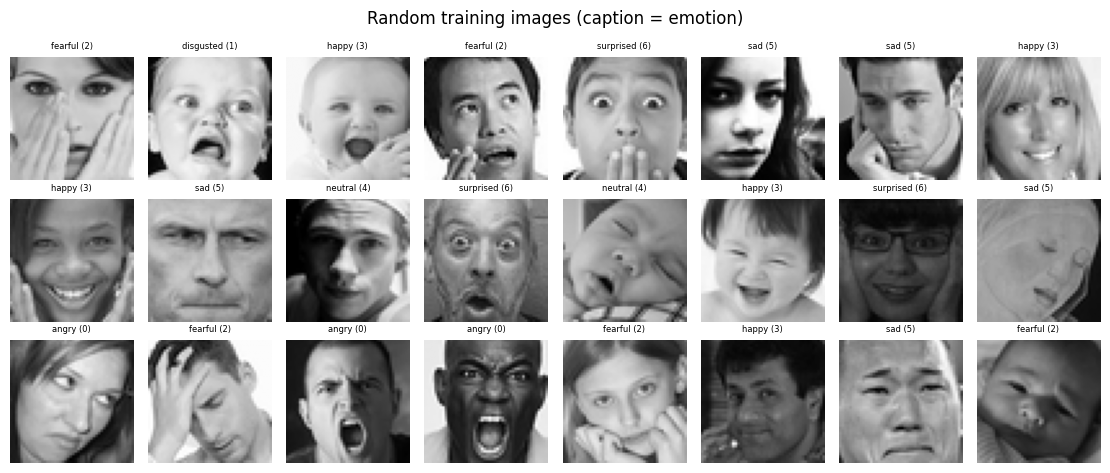

In [27]:
# CELL 27: Preview images with their labels
sample = img_df[img_df.split == 'train'].sample(24, random_state=SEED)   # 24 random training images
show_grid(sample.path, 'Random training images (caption = emotion)', 'A1_preview',
          labels=[f'{e} ({l})' for e, l in zip(sample.emotion, sample.label)])

**Explanation of Cell 27: Preview images with their labels**

- **Purpose:** look at real images with their assigned emotion and label.
- **Output:** a grid; each caption is `emotion (label)`.
- **Saved as:** `A1_preview.png`.
- **What to check:** images are faces (not empty), and the captions look plausible. A few wrong-looking labels are normal for this kind of dataset.

---
# Part B: Exploratory Data Analysis (EDA)

Part B audits the table built in Part A. Thresholds for "blurry", "too dark" and so on are the starting values from the analysis-settings cell; confirm them with the sample grids before using them to filter data.

## 2.1 Class distribution

In [28]:
# CELL 28: Images per emotion and split (percent)
# share of each emotion inside its own split, in percent
share = (pd.crosstab(img_df.emotion, img_df.split, normalize='columns') * 100).round(1).reindex(columns=list(SPLITS))
share.to_csv(OUT / 'class_share_pct.csv')
share

split,train,test
emotion,,
angry,13.9,13.3
disgusted,1.5,1.5
fearful,14.3,14.3
happy,25.1,24.7
neutral,17.3,17.2
sad,16.9,17.4
surprised,11.0,11.6


**Explanation of Cell 28: Images per emotion and split (percent)**

- **Purpose:** the share of each emotion inside train and inside test.
- **File:** `class_share_pct.csv`.
- **What to check:** if the train and test shares are close, the test set is representative of the training set. A big gap means test accuracy will not match the training distribution.

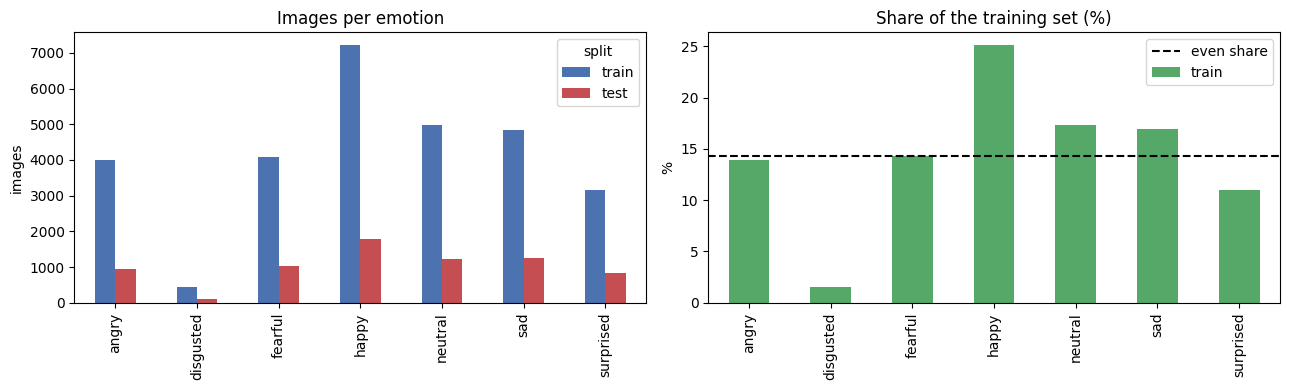

In [29]:
# CELL 29: Chart: images per emotion
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
# left: absolute number of images per emotion, train and test side by side
counts.drop(index='TOTAL')[list(SPLITS)].plot.bar(ax=axes[0], color=['#4C72B0', '#C44E52'])
axes[0].set(title='Images per emotion', ylabel='images', xlabel='')
# right: share of each emotion in the training set
share['train'].plot.bar(ax=axes[1], color='#55A868')
axes[1].axhline(100 / len(label_map), color='k', ls='--', label='even share')
axes[1].set(title='Share of the training set (%)', ylabel='%', xlabel='')
axes[1].legend()
savefig('B1_images_per_emotion')

**Explanation of Cell 29: Chart: images per emotion**

- **Purpose:** show the class distribution as a picture.
- **Left:** number of images per emotion in train and test.
- **Right:** share of each emotion in train. The dashed line is the share each class would have in a perfectly balanced set (1 / 7, about 14.3%).
- **Saved as:** `B1_images_per_emotion.png`.

In [30]:
# CELL 30: Imbalance statistics
c = counts.drop(index='TOTAL')['train']                     # training images per emotion
gini = (2 * np.arange(1, len(c) + 1) - len(c) - 1).dot(np.sort(c.values)) / (len(c) * c.sum())
imbalance = pd.Series({
    'classes': len(c),
    'largest class': f'{c.idxmax()} ({c.max():,})',
    'smallest class': f'{c.idxmin()} ({c.min():,})',
    'largest / smallest (imbalance ratio)': round(c.max() / c.min(), 1),
    'smallest class share (%)': round(c.min() / c.sum() * 100, 2),
    'Gini coefficient (0 = perfectly even)': round(gini, 3),
}, name='value')
imbalance.to_csv(OUT / 'class_imbalance.csv')
imbalance

,value
classes,7
largest class,"happy (7,215)"
smallest class,disgusted (436)
largest / smallest (imbalance ratio),16.5
smallest class share (%),1.52
Gini coefficient (0 = perfectly even),0.246


**Explanation of Cell 30: Imbalance statistics**

- **Purpose:** put a number on the imbalance.
- **Imbalance ratio:** the largest class divided by the smallest. A ratio above about 5 means the model will probably ignore the rare class unless we compensate.
- **Gini:** 0 = every class has the same number of images; 1 = very uneven.
- **File:** `class_imbalance.csv`.

In [31]:
# CELL 31: Class weights for training
# "balanced" weight = total / (number of classes * images in the class): rare classes get a larger weight
class_weights = (c.sum() / (len(c) * c)).round(3).rename('weight').rename_axis('emotion').reset_index()
class_weights['label'] = class_weights.emotion.map(label_map)
class_weights.to_csv(OUT / 'class_weights.csv', index=False)
class_weights

,emotion,weight,label
0,angry,1.028,0
1,disgusted,9.411,1
2,fearful,1.001,2
3,happy,0.569,3
4,neutral,0.826,4
5,sad,0.847,5
6,surprised,1.294,6


**Explanation of Cell 31: Class weights for training**

- **Purpose:** compute a weight for every class, to be passed to the loss function during training (for example `CrossEntropyLoss(weight=...)`) so that errors on rare emotions count more.
- **Formula:** `total images / (number of classes x images in the class)`. A weight of 1 means "average"; a weight of 8 means the class is 8 times rarer than average.
- **File:** `class_weights.csv`. The training notebook can load it directly.

## 2.2 Image quality

In [32]:
# CELL 32: Scan the images
# Slowest cell: open the images and measure each one
q = scan_many(img_df, SCAN_FRACTION, 'scanning images')
q.to_csv(OUT / 'image_quality.csv', index=False)
print(f'scanned {len(q):,} of {len(img_df):,} images | corrupted: {int(q.corrupt.sum())}')

scanning images:   0%|          | 0/7180 [00:00<?, ?it/s]

scanned 7,180 of 35,899 images | corrupted: 0


**Explanation of Cell 32: Scan the images**

- **Purpose:** measure the images (all, or a random `SCAN_FRACTION`).
- **Variable:** `q` (all scanned images, including corrupted ones). **File:** `image_quality.csv`.
- **Output:** progress bar, then scanned and corrupted counts.
- **Time:** about a minute with a zip, longer from Drive. If the runtime disconnects, run the cell again.

In [33]:
# CELL 33: Keep only the readable images
# ok = images that could be opened; corrupted ones are reported separately
ok = q[~q.corrupt]
bad = q[q.corrupt]
print(f'readable: {len(ok):,} | corrupted: {len(bad)}')

readable: 7,180 | corrupted: 0


**Explanation of Cell 33: Keep only the readable images**

- **Purpose:** split the scan into `ok` (readable, used by all charts) and `bad` (corrupted).
- **Output:** the two counts.

In [34]:
# CELL 34: Image sizes, formats and colour modes
# most common sizes per split
size_counts = (ok.assign(size=ok.width.astype(int).astype(str) + 'x' + ok.height.astype(int).astype(str))
                 .groupby(['split', 'size']).size().rename('images').reset_index()
                 .sort_values('images', ascending=False))
# file format + colour mode per split
fmt_mode = ok.groupby(['split', 'format', 'mode']).size().rename('images').reset_index()
size_counts.to_csv(OUT / 'image_sizes.csv', index=False)
fmt_mode.to_csv(OUT / 'formats_and_modes.csv', index=False)

display(size_counts.head(10))
fmt_mode

,split,size,images
1,train,48x48,5707
0,test,48x48,1473


,split,format,mode,images
0,test,PNG,L,1473
1,train,PNG,L,5707


**Explanation of Cell 34: Image sizes, formats and colour modes**

- **Purpose:** find which sizes, formats and colour modes exist.
- **Output:** two tables. Expect one size (about 48x48), PNG, greyscale (mode `L`).
- **What to check:** several sizes or modes mean preprocessing must convert everything to one input size and one channel count. Note: the face recognition images are 64x64 RGB, so this model needs its own preprocessing.
- **Files:** `image_sizes.csv`, `formats_and_modes.csv`.

In [35]:
# CELL 35: Function: quality_table
def quality_table(ok, bad, by):
    # count how many images of each group (split or emotion) fall under each quality flag
    t = ok.groupby(by).agg(
        images=('path', 'size'),
        low_res=('short_side', lambda s: int((s < LOW_RES_PX).sum())),
        blurry=('blur', lambda s: int((s < BLUR_THR).sum())),
        too_dark=('brightness', lambda s: int((s < DARK).sum())),
        too_bright=('brightness', lambda s: int((s > BRIGHT).sum())),
        low_contrast=('contrast', lambda s: int((s < LOW_CONTRAST).sum())),
    )
    # corrupted images come from the separate table
    t.insert(1, 'corrupted', bad.groupby(by).size().reindex(t.index).fillna(0).astype(int))
    return t.fillna(0).astype(int)

**Explanation of Cell 35: Function: quality_table**

- **Purpose:** count, per group, the images under each quality flag: corrupted, low-resolution, blurry, too dark, too bright, low-contrast (thresholds from the settings cell).
- **Arguments:** `ok` readable images, `bad` corrupted images, `by` the column to group by (`'split'` or `'emotion'`).
- **Output:** none (defines the function only).

In [36]:
# CELL 36: Quality flags per split
quality_split = quality_table(ok, bad, 'split')
quality_split.to_csv(OUT / 'quality_flags_by_split.csv')
bad[['split', 'emotion', 'path', 'error']].to_csv(OUT / 'corrupted_files.csv', index=False)   # which files are broken
quality_split

,images,corrupted,low_res,blurry,too_dark,too_bright,low_contrast
split,,,,,,,
test,1473,0,0,0,6,23,6
train,5707,0,0,5,19,76,14


**Explanation of Cell 36: Quality flags per split**

- **Purpose:** the quality table per split.
- **Files:** `quality_flags_by_split.csv`, `corrupted_files.csv`.
- **How to read it:** a flag is a **warning, not an instruction to delete**. Look at the sample grids before removing images.

In [37]:
# CELL 37: Quality flags per emotion
quality_emotion = quality_table(ok, bad, 'emotion')
quality_emotion.to_csv(OUT / 'quality_flags_by_emotion.csv')
quality_emotion

,images,corrupted,low_res,blurry,too_dark,too_bright,low_contrast
emotion,,,,,,,
angry,1004,0,0,0,1,9,1
disgusted,102,0,0,0,0,5,0
fearful,1079,0,0,1,2,15,3
happy,1785,0,0,1,5,23,4
neutral,1225,0,0,1,2,11,8
sad,1215,0,0,1,13,7,2
surprised,770,0,0,1,2,29,2


**Explanation of Cell 37: Quality flags per emotion**

- **Purpose:** the same flags per emotion. This reveals whether one emotion is systematically darker or blurrier than the others, which a model could pick up as a shortcut instead of learning the expression.
- **File:** `quality_flags_by_emotion.csv`.

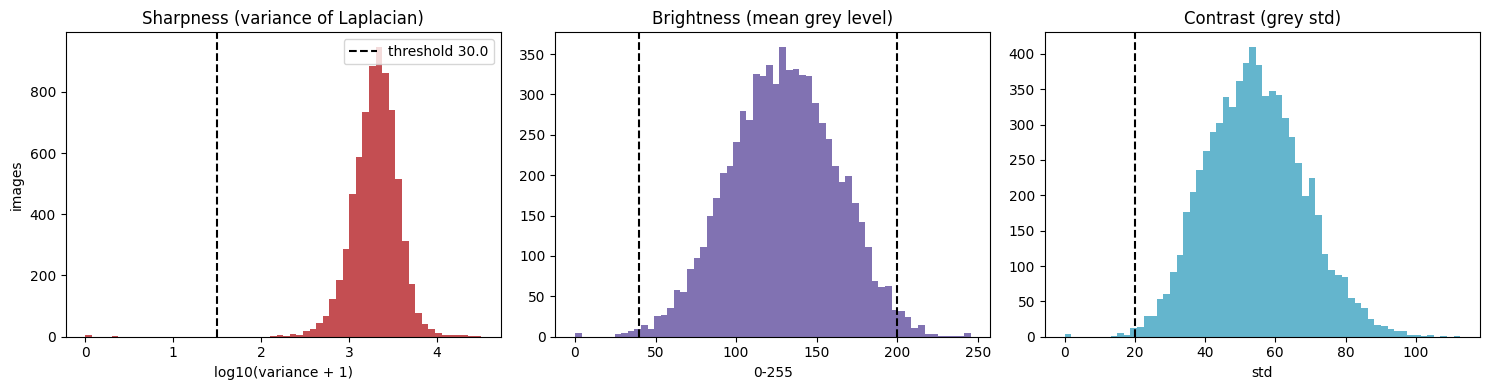

sharpness percentiles: {0.01: 418.8, 0.05: 748.1, 0.25: 1400.6, 0.5: 2052.6}


In [38]:
# CELL 38: Charts: sharpness, brightness and contrast
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
# sharpness on a log scale; left of the dashed line = flagged blurry
axes[0].hist(np.log10(ok.blur + 1), bins=60, color='#C44E52')
axes[0].axvline(np.log10(BLUR_THR + 1), color='k', ls='--', label=f'threshold {BLUR_THR}')
axes[0].set(title='Sharpness (variance of Laplacian)', xlabel='log10(variance + 1)', ylabel='images')
axes[0].legend()
# brightness; outside the two dashed lines = too dark / too bright
axes[1].hist(ok.brightness, bins=60, color='#8172B2')
for t in (DARK, BRIGHT):
    axes[1].axvline(t, color='k', ls='--')
axes[1].set(title='Brightness (mean grey level)', xlabel='0-255')
# contrast; left of the dashed line = low contrast
axes[2].hist(ok.contrast, bins=60, color='#64B5CD')
axes[2].axvline(LOW_CONTRAST, color='k', ls='--')
axes[2].set(title='Contrast (grey std)', xlabel='std')
savefig('B2_quality_distributions')

# low percentiles of sharpness, quoted in the summary
blur_pct = ok.blur.quantile([0.01, 0.05, 0.25, 0.5]).round(1)
print('sharpness percentiles:', blur_pct.to_dict())

**Explanation of Cell 38: Charts: sharpness, brightness and contrast**

- **Purpose:** show where the thresholds sit in the real distributions.
- **What to check:** a threshold inside a big peak would flag half the dataset; it should sit in the low tail.
- **Variable:** `blur_pct`. **Saved as:** `B2_quality_distributions.png`.

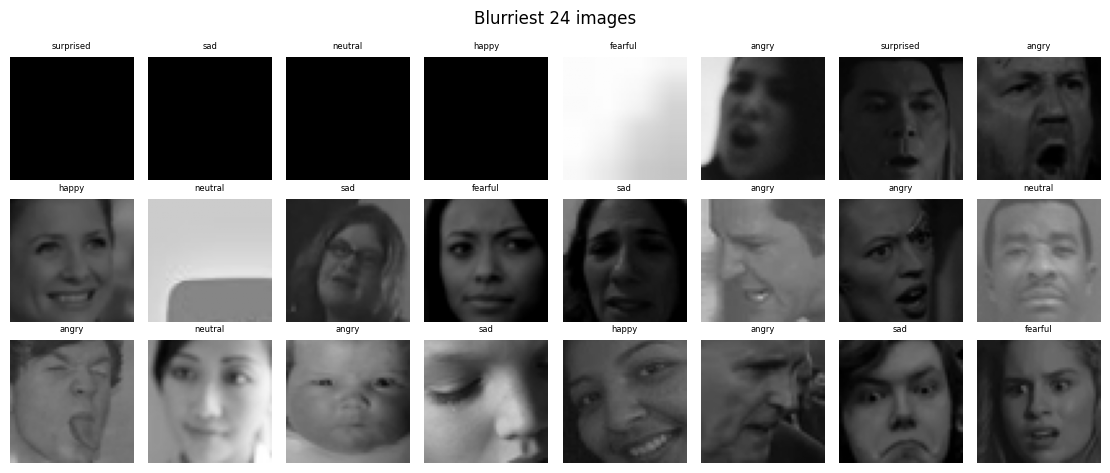

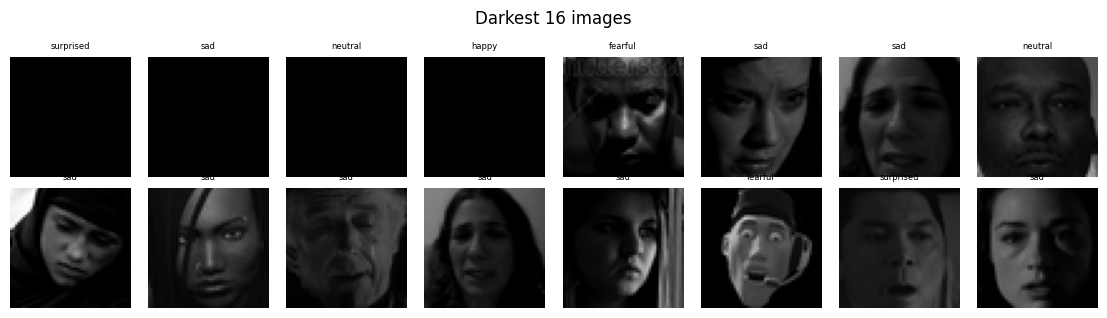

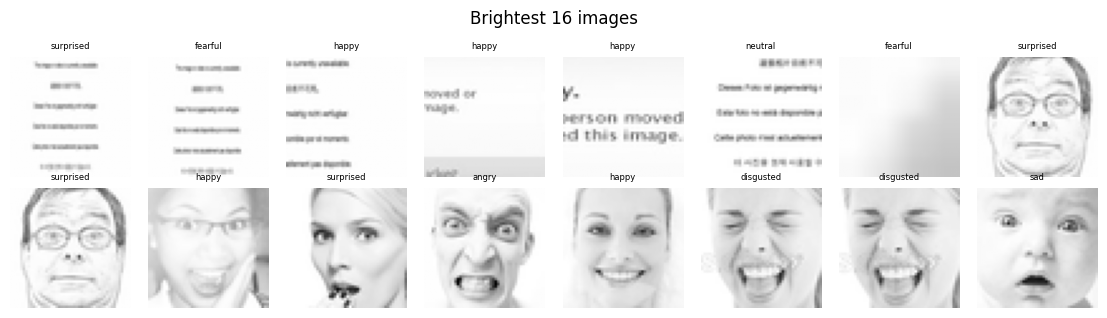

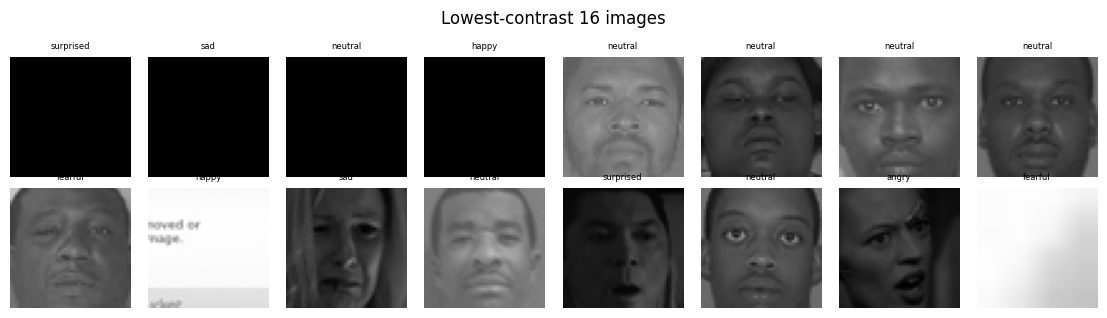

In [39]:
# CELL 39: Sample grids of the extreme images
# look at the extremes: a number cannot tell if a "dark" image is still a usable face
show_grid(ok.nsmallest(24, 'blur').path, 'Blurriest 24 images', 'B2_grid_blurriest')
show_grid(ok.nsmallest(16, 'brightness').path, 'Darkest 16 images', 'B2_grid_darkest')
show_grid(ok.nlargest(16, 'brightness').path, 'Brightest 16 images', 'B2_grid_brightest')
show_grid(ok.nsmallest(16, 'contrast').path, 'Lowest-contrast 16 images', 'B2_grid_low_contrast')

**Explanation of Cell 39: Sample grids of the extreme images**

- **Purpose:** inspect the extreme images by eye. In emotion datasets, extreme images are often not faces at all (blank, cartoons, watermarks).
- **What to check:** if the worst images are still clear faces, the thresholds are too strict. If they are blank or not faces, they should be removed.
- **Saved as:** `B2_grid_blurriest.png`, `B2_grid_darkest.png`, `B2_grid_brightest.png`, `B2_grid_low_contrast.png`.

## 2.3 What each emotion looks like

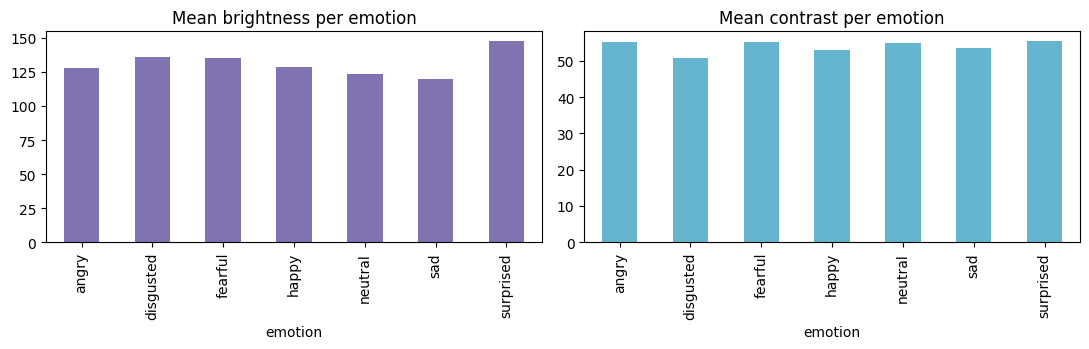

,brightness,contrast,sharpness
emotion,,,
angry,127.5,55.3,2222.4
disgusted,135.9,50.7,1616.6
fearful,135.4,55.3,2169.9
happy,128.7,53.0,1980.5
neutral,123.7,54.9,1967.8
sad,120.0,53.5,1788.0
surprised,147.4,55.4,2444.0


In [40]:
# CELL 40: Brightness and contrast per emotion
# average brightness and contrast of each emotion
look = ok.groupby('emotion').agg(brightness=('brightness', 'mean'), contrast=('contrast', 'mean'),
                                 sharpness=('blur', 'median')).round(1)
look.to_csv(OUT / 'emotion_appearance.csv')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
look.brightness.plot.bar(ax=axes[0], color='#8172B2', title='Mean brightness per emotion')
look.contrast.plot.bar(ax=axes[1], color='#64B5CD', title='Mean contrast per emotion')
savefig('B3_appearance_per_emotion')
look

**Explanation of Cell 40: Brightness and contrast per emotion**

- **Purpose:** check whether the emotions differ in simple image statistics.
- **What to check:** bars of similar height are good. If one emotion is much brighter or has much higher contrast, the model could learn "brightness" instead of "expression". Data augmentation (random brightness and contrast) reduces that risk.
- **File:** `emotion_appearance.csv`. **Saved as:** `B3_appearance_per_emotion.png`.

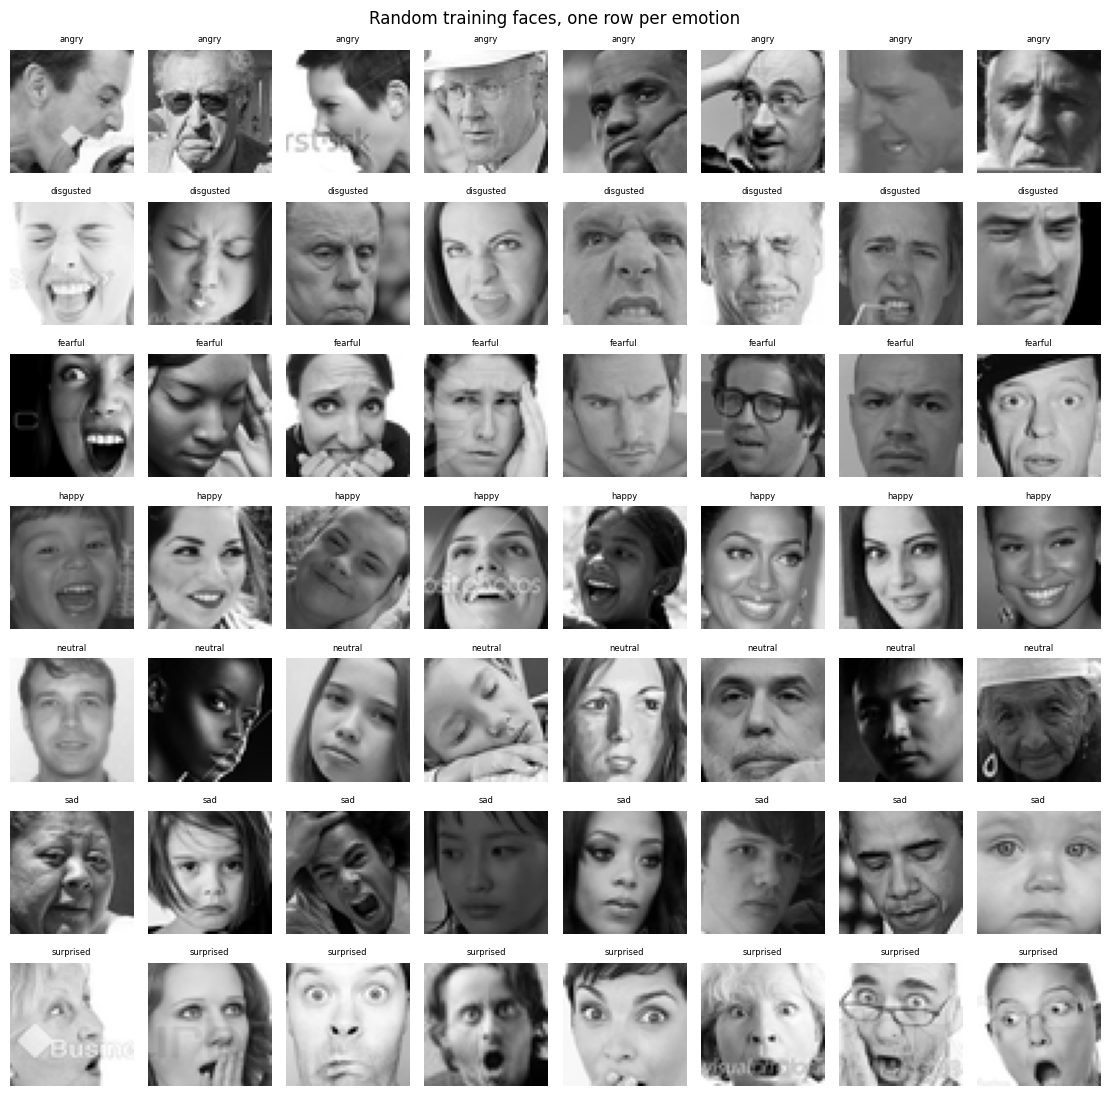

In [41]:
# CELL 41: Sample faces for every emotion
# one row of N faces per emotion, so each emotion can be judged by eye
paths, caps = [], []
for emo in emotions:
    part = ok[(ok.split == 'train') & (ok.emotion == emo)]
    pick = part.sample(min(N_PER_CLASS_GRID, len(part)), random_state=SEED)
    paths += list(pick.path)
    caps += [emo] * len(pick)
show_grid(paths, 'Random training faces, one row per emotion', 'B3_faces_per_emotion',
          ncols=N_PER_CLASS_GRID, labels=caps)

**Explanation of Cell 41: Sample faces for every emotion**

- **Purpose:** look at what each emotion really contains. This is the most useful check in this notebook.
- **Output:** one row per emotion, in the order of the label map.
- **What to check:** does every row show the expression in its caption? Wrong-looking images are **label noise**; a few are normal, many suggest the dataset needs cleaning. Also note which emotions look similar (for example fearful and surprised), because the model will confuse them too.
- **Saved as:** `B3_faces_per_emotion.png`.

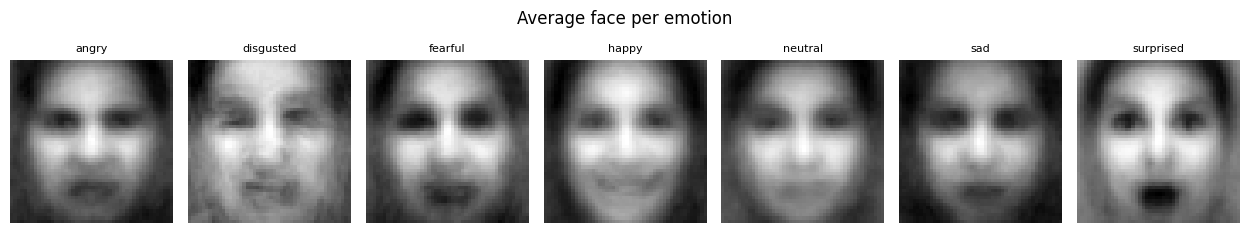

In [42]:
# CELL 42: Average face of every emotion
# average several images of one emotion pixel by pixel; the expression shows as a blurry template
fig, axes = plt.subplots(1, len(emotions), figsize=(len(emotions) * 1.8, 2.4))
for ax, emo in zip(axes, emotions):
    part = ok[(ok.split == 'train') & (ok.emotion == emo)]
    pick = part.sample(min(N_MEAN_FACE, len(part)), random_state=SEED)
    stack = [np.asarray(Image.open(p).convert('L').resize((48, 48)), dtype=np.float32) for p in pick.path]
    ax.imshow(np.mean(stack, axis=0), cmap='gray')     # the average image
    ax.set_title(emo, fontsize=8)
    ax.axis('off')
fig.suptitle('Average face per emotion')
savefig('B3_mean_face_per_emotion')

**Explanation of Cell 42: Average face of every emotion**

- **Purpose:** show the typical face of each emotion. Features that are always in the same place (open mouth for surprised, raised cheeks for happy) appear sharp; features that vary appear blurred.
- **What to check:** the averages should look like faces, with some difference between emotions. If all seven look identical, expressions are subtle and the task is hard.
- **Saved as:** `B3_mean_face_per_emotion.png`.

## 2.4 Duplicates and label noise

- **Exact duplicates**: identical file bytes (same MD5). **Near duplicates**: identical perceptual hash.
- The same picture under **two different emotions** is a clear **labelling conflict**: at least one label is wrong.
- The same picture **across train and test** is **leakage** (section 2.5).

In [43]:
# CELL 43: Function: dup_groups
def dup_groups(df, key):
    # keep only rows whose hash appears more than once
    sizes = df.groupby(key).path.transform('size')
    d = df[sizes > 1].copy()
    if d.empty:
        return d.assign(group_type=pd.Series(dtype=str))
    # how many splits / emotions does each duplicate group touch?
    agg = d.groupby(key).agg(n_splits=('split', 'nunique'), n_emotions=('emotion', 'nunique'))
    d = d.join(agg, on=key)
    d['group_type'] = np.select(
        [d.n_emotions > 1, d.n_splits > 1],          # a label conflict is checked first: it is the more serious finding
        ['different emotions (label conflict)', 'across splits'],
        'same emotion')
    return d.sort_values([key, 'split'])

**Explanation of Cell 43: Function: dup_groups**

- **Purpose:** find images sharing a hash and label each group:
  - `same emotion`: copies with the same label; harmless but wasted;
  - `different emotions (label conflict)`: the same picture carries two labels, so at least one is wrong;
  - `across splits`: **data leakage** between train and test (groups that are also label conflicts are counted as conflicts; the leakage tables in section 2.5 count every shared image regardless).
- **Arguments:** `df` scanned images, `key` = `'md5'` or `'phash'`.
- **Output:** none (defines the function only).

In [44]:
# CELL 44: Find exact duplicates
exact = dup_groups(ok, 'md5')                         # identical files
exact.to_csv(OUT / 'duplicates_exact.csv', index=False)
print(f'{len(exact):,} images belong to {exact.md5.nunique() if len(exact) else 0} exact-duplicate groups')

179 images belong to 85 exact-duplicate groups


**Explanation of Cell 44: Find exact duplicates**

- **Purpose:** find identical files (same MD5).
- **Variable:** `exact`. **File:** `duplicates_exact.csv` (every image in a duplicate group, so the team can open them).

In [45]:
# CELL 45: Find near duplicates
# search only images that are NOT already exact duplicates, so nothing is counted twice
near = dup_groups(ok[~ok.md5.isin(exact.md5)], 'phash')
near.to_csv(OUT / 'duplicates_near.csv', index=False)
print(f'{len(near):,} images belong to {near.phash.nunique() if len(near) else 0} near-duplicate groups')

15 images belong to 7 near-duplicate groups


**Explanation of Cell 45: Find near duplicates**

- **Purpose:** find re-encoded or resized copies (same perceptual hash). On small 48x48 faces, different pictures can occasionally share a hash, so check some groups by eye.
- **Variable:** `near`. **File:** `duplicates_near.csv`.

In [46]:
# CELL 46: Duplicate summary table
dup_summary = pd.DataFrame({
    'exact (md5)': exact.groupby('group_type').md5.nunique() if len(exact) else pd.Series(dtype=int),
    'near (pHash)': near.groupby('group_type').phash.nunique() if len(near) else pd.Series(dtype=int),
}).fillna(0).astype(int)
dup_summary.index.name = 'duplicate groups'
dup_summary.to_csv(OUT / 'duplicate_summary.csv')
dup_summary

,exact (md5),near (pHash)
duplicate groups,,
across splits,23,2
different emotions (label conflict),5,0
same emotion,57,5


**Explanation of Cell 46: Duplicate summary table**

- **Purpose:** number of duplicate groups of each type.
- **What to check:** `across splits` should be 0. `different emotions (label conflict)` shows label noise; those images should be reviewed or removed.
- **Note:** with `SCAN_FRACTION` below 1 the real numbers are higher.

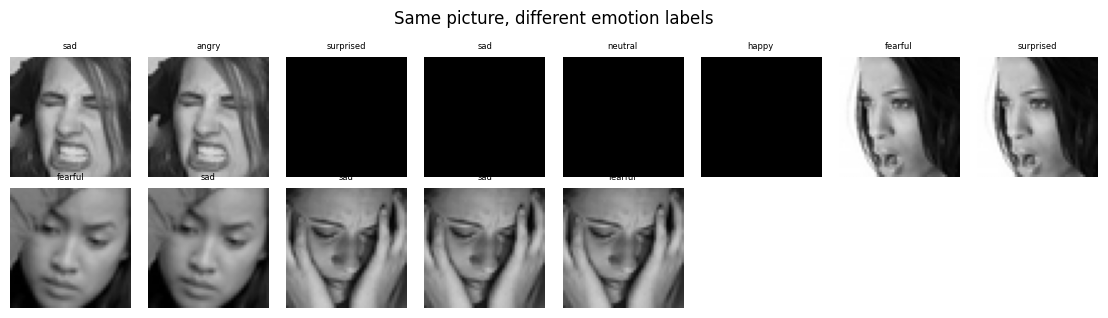

In [47]:
# CELL 47: Grid: images with conflicting labels
# show images that appear under two different emotions (the caption shows the label each copy carries)
conflict = pd.concat([exact, near]) if len(exact) or len(near) else exact
conflict = conflict[conflict.group_type == 'different emotions (label conflict)'] if len(conflict) else conflict
if len(conflict):
    sel = conflict.head(24)
    show_grid(sel.path, 'Same picture, different emotion labels', 'B4_label_conflicts', labels=sel.emotion)
else:
    print('no label conflicts found among the scanned images')

**Explanation of Cell 47: Grid: images with conflicting labels**

- **Purpose:** look at the label conflicts directly.
- **Output:** a grid of up to 24 images; the caption is the label each copy carries. The same face appearing with two captions proves that at least one label is wrong.
- **Saved as:** `B4_label_conflicts.png` (only when conflicts exist).

## 2.5 Leakage and validation split

In [48]:
# CELL 48: Function: overlap_matrix
def overlap_matrix(df, key, groups):
    # for every pair of groups, count how many hashes (images) they share
    sets = {s: set(df[df.split == s][key]) for s in groups}
    return pd.DataFrame([[len(sets[a] & sets[b]) if a != b else np.nan for b in groups] for a in groups],
                        index=groups, columns=groups)

**Explanation of Cell 48: Function: overlap_matrix**

- **Purpose:** count how many images two splits have in common.
- **Arguments:** `df` scanned images, `key` = `'md5'` or `'phash'`, `groups` split names.
- **Returns:** a square table; the diagonal is empty.
- **Output:** none (defines the function only).

In [49]:
# CELL 49: Identical images shared between train and test (MD5)
leak_exact = overlap_matrix(ok, 'md5', list(SPLITS))
leak_exact.to_csv(OUT / 'leakage_exact_image_overlap.csv')
leak_exact

,train,test
train,NaN,24.0
test,24.0,NaN


**Explanation of Cell 49: Identical images shared between train and test (MD5)**

- **Purpose:** do train and test share any identical picture?
- **What to check:** the number should be **0**. A positive number means test images were also seen in training, so the test accuracy is too optimistic.
- **File:** `leakage_exact_image_overlap.csv`.

In [50]:
# CELL 50: Near-identical images shared between train and test (pHash)
leak_near = overlap_matrix(ok, 'phash', list(SPLITS))
leak_near.to_csv(OUT / 'leakage_near_image_overlap.csv')
leak_near

,train,test
train,NaN,26.0
test,26.0,NaN


**Explanation of Cell 50: Near-identical images shared between train and test (pHash)**

- **Purpose:** the same check for near copies (includes the identical ones).
- **File:** `leakage_near_image_overlap.csv`.
- **Note:** with `SCAN_FRACTION` below 1 only scanned images are compared, so real overlap is larger.

In [51]:
# CELL 51: Create a validation split from the training data
# The dataset has no validation folder: set aside VAL_FRACTION of every emotion in train (stratified)
rng = np.random.default_rng(SEED)
img_df['subset'] = img_df.split                       # start from the official split
train_rows = img_df[img_df.split == 'train']
for emo, part in train_rows.groupby('emotion'):
    n_val = max(1, int(round(len(part) * VAL_FRACTION)))
    val_idx = rng.choice(part.index.values, size=n_val, replace=False)   # random images of this emotion
    img_df.loc[val_idx, 'subset'] = 'val'

split_check = pd.crosstab(img_df.emotion, img_df.subset)[['train', 'val', 'test']]
img_df[['subset', 'emotion', 'label', 'path']].to_csv(OUT / 'emotion_inventory_with_val.csv', index=False)
split_check

subset,train,val,test
emotion,,,
angry,3593,399,958
disgusted,392,44,111
fearful,3687,410,1024
happy,6493,722,1774
neutral,4469,497,1233
sad,4360,484,1247
surprised,2854,317,831


**Explanation of Cell 51: Create a validation split from the training data**

- **Purpose:** the dataset has only train and test. A model needs a separate **validation** set to choose settings (learning rate, epochs) without touching the test set. This cell sets aside `VAL_FRACTION` (10%) of the training images, **separately for each emotion** so that rare emotions keep their share (a *stratified* split).
- **Result:** the column `subset` (`train`, `val` or `test`) in `img_df`; the original `split` column is unchanged.
- **File:** `emotion_inventory_with_val.csv`. Training notebooks should use this file so that everyone has the **same** validation images (the seed is fixed).
- **Output:** a table of images per emotion and subset.
- **Caution:** duplicates that fall into different subsets would leak; remove duplicates (section 2.4) before using the split for the final model.

## 2.6 Summary and handoff

The cells below build a plain-text summary (`EDA_summary.md`), an HTML report and copy everything to Google Drive.

In [52]:
# CELL 52: Summary: dataset size and balance
n_train, n_test = (img_df.split == 'train').sum(), (img_df.split == 'test').sum()
lines = [                                                  # `lines` collects one text line per finding
    '# Emotion detection EDA: summary', '',
    '## Dataset size',
    f"- Training: {fmt_int(n_train)} images; test: {fmt_int(n_test)} images; no official validation split.",
    f"- Emotions ({len(label_map)}): " + ', '.join(f'{e} ({l})' for e, l in label_map.items()) + '.',
    '', '## Class balance',
    f"- Largest class: {imbalance['largest class']}; smallest class: {imbalance['smallest class']}.",
    f"- Imbalance ratio {imbalance['largest / smallest (imbalance ratio)']}; Gini {imbalance['Gini coefficient (0 = perfectly even)']}.",
    f"- Smallest class holds {imbalance['smallest class share (%)']}% of the training images (an even share would be {100 / len(label_map):.1f}%).",
]
print(len(lines), 'lines so far')

10 lines so far


**Explanation of Cell 52: Summary: dataset size and balance**

- **Purpose:** start the written summary from the tables above, so nobody retypes numbers.
- **Variable:** `lines`, a list with one text line per finding. Later summary cells add to it.
- **If it fails with `NameError`:** a cell above was not run; the error names it.

In [53]:
# CELL 53: Summary: image quality and duplicates
lines += ['', '## Image properties and quality']
lines.append(f"- Scan coverage: {SCAN_FRACTION:.0%} of the images.")
top_sizes = size_counts.groupby('size').images.sum().sort_values(ascending=False).head(3)
lines.append('- Sizes: ' + ', '.join(f'{k} ({fmt_int(v)})' for k, v in top_sizes.items()) + '.')
lines.append('- Formats / modes: ' + ', '.join(f'{f} {m} ({fmt_int(cnt)})' for (f, m), cnt in
             ok.groupby(['format', 'mode']).size().items()) + '.')
tot = quality_split.sum()                                  # flags summed over both splits
lines.append(f"- Flags: {fmt_int(tot.corrupted)} corrupted, {fmt_int(tot.low_res)} low-resolution (<{LOW_RES_PX}px), "
             f"{fmt_int(tot.blurry)} blurry (Laplacian variance <{BLUR_THR}), {fmt_int(tot.too_dark)} too dark, "
             f"{fmt_int(tot.too_bright)} too bright, {fmt_int(tot.low_contrast)} low contrast.")
lines.append(f"- Sharpness percentiles (1st, 5th, 25th, 50th): {', '.join(str(v) for v in blur_pct.values)}.")
lines.append(f"- Duplicate groups: {fmt_int(exact.md5.nunique() if len(exact) else 0)} exact, "
             f"{fmt_int(near.phash.nunique() if len(near) else 0)} near-duplicate.")
print(len(lines), 'lines so far')

18 lines so far


**Explanation of Cell 53: Summary: image quality and duplicates**

- **Purpose:** add scan coverage, sizes, formats, quality flags, sharpness percentiles and duplicate groups to `lines`.

In [54]:
# CELL 54: Summary: appearance, leakage and validation split
lines += ['', '## Appearance per emotion']
lines.append(f"- Mean brightness ranges from {look.brightness.min()} ({look.brightness.idxmin()}) to {look.brightness.max()} ({look.brightness.idxmax()}).")
lines.append(f"- Mean contrast ranges from {look.contrast.min()} ({look.contrast.idxmin()}) to {look.contrast.max()} ({look.contrast.idxmax()}).")

lines += ['', '## Leakage and label noise']
n_leak = int(np.nansum(leak_exact.values) // 2)
n_leak_near = int(np.nansum(leak_near.values) // 2)
if n_leak or n_leak_near:
    lines.append(f"- LEAKAGE: {n_leak} identical and {n_leak_near} near-identical images are shared between train and test.")
else:
    lines.append('- No identical or near-identical images are shared between train and test.')
n_conf = exact[exact.group_type == 'different emotions (label conflict)'].md5.nunique() if len(exact) else 0
lines.append(f"- Label conflicts (same picture, different emotions): {fmt_int(n_conf)} exact groups.")

lines += ['', '## Validation split']
lines.append(f"- Created from train: {fmt_int((img_df.subset == 'val').sum())} images ({VAL_FRACTION:.0%} per emotion, seed {SEED}); see emotion_inventory_with_val.csv.")
print(len(lines), 'lines so far')

29 lines so far


**Explanation of Cell 54: Summary: appearance, leakage and validation split**

- **Purpose:** add appearance differences between emotions, leakage and label conflicts, and the validation split.

In [55]:
# CELL 55: Summary: suggested rules, then write EDA_summary.md
lines += ['', '## Suggested cleaning and training rules (for team decision)',
          '- Remove corrupted files listed in corrupted_files.csv.',
          '- Remove blank or non-face images found in the extreme-image grids (confirm thresholds first).',
          '- Remove test images that also appear in train, and review images that carry two different labels.',
          f"- Use class weights (class_weights.csv) or balanced sampling: the imbalance ratio is {imbalance['largest / smallest (imbalance ratio)']}.",
          '- Report macro-F1 and a confusion matrix, not only accuracy, because accuracy hides weak rare classes.',
          '- Use the validation split from emotion_inventory_with_val.csv; never tune on the test set.',
          '- Use brightness / contrast augmentation, horizontal flips and small rotations; avoid flips that change the meaning.',
          '- Expect noisy labels: some confusion between similar emotions (fearful / surprised, sad / neutral) is normal.']

summary_text = '\n'.join(lines)
(OUT / 'EDA_summary.md').write_text(summary_text, encoding='utf-8')   # save to file
print(summary_text)

# Emotion detection EDA: summary

## Dataset size
- Training: 28,721 images; test: 7,178 images; no official validation split.
- Emotions (7): angry (0), disgusted (1), fearful (2), happy (3), neutral (4), sad (5), surprised (6).

## Class balance
- Largest class: happy (7,215); smallest class: disgusted (436).
- Imbalance ratio 16.5; Gini 0.246.
- Smallest class holds 1.52% of the training images (an even share would be 14.3%).

## Image properties and quality
- Scan coverage: 20% of the images.
- Sizes: 48x48 (7,180).
- Formats / modes: PNG L (7,180).
- Flags: 0 corrupted, 0 low-resolution (<40px), 5 blurry (Laplacian variance <30.0), 25 too dark, 99 too bright, 20 low contrast.
- Sharpness percentiles (1st, 5th, 25th, 50th): 418.8, 748.1, 1400.6, 2052.6.
- Duplicate groups: 85 exact, 7 near-duplicate.

## Appearance per emotion
- Mean brightness ranges from 120.0 (sad) to 147.4 (surprised).
- Mean contrast ranges from 50.7 (disgusted) to 55.4 (surprised).

## Leakage and label noise

**Explanation of Cell 55: Summary: suggested rules, then write EDA_summary.md**

- **Purpose:** finish the summary, save `EDA_summary.md` and print it.
- **Suggested rules** are **proposals for the team to approve**; nothing on Drive is modified.
- **Output:** the full summary: read this first and paste it into the report.

In [56]:
# CELL 56: HTML helper: img_tag
def img_tag(name):
    p = OUT / f'{name}.png'
    if not p.exists():                       # a chart that was not produced
        return ''
    b64 = base64.b64encode(p.read_bytes()).decode()      # embed the PNG as text
    return f'<img src="data:image/png;base64,{b64}" style="max-width:100%;margin:8px 0">'

**Explanation of Cell 56: HTML helper: img_tag**

- **Purpose:** embed a saved chart PNG inside the HTML (base64), so the report is a **single file**.
- **Returns:** an `<img>` tag, or an empty string if the chart does not exist.
- **Output:** none (defines the function only).

In [57]:
# CELL 57: HTML helper: table
def table(df, title):
    # heading + the pandas table as HTML
    return f'<h3>{html.escape(title)}</h3>' + df.to_html(border=0, classes='t', na_rep='-')

**Explanation of Cell 57: HTML helper: table**

- **Purpose:** turn a pandas table into an HTML table with a heading.
- **Output:** none (defines the function only).

In [58]:
# CELL 58: HTML style (css)
css = ('body{font-family:Arial,sans-serif;max-width:980px;margin:24px auto;padding:0 16px}'
       'table.t{border-collapse:collapse;font-size:13px}table.t td,table.t th{border:1px solid #ccc;padding:3px 8px}'
       'th{background:#f1f1f1}')

**Explanation of Cell 58: HTML style (css)**

- **Purpose:** the page style (font, table borders). Edit here to change how the report looks.

In [59]:
# CELL 59: Convert the summary to HTML
# "# " -> h1, "## " -> h2, "- " -> list item
summary_html = ''.join(
    f'<h2>{html.escape(l[3:])}</h2>' if l.startswith('## ') else
    f'<h1>{html.escape(l[2:])}</h1>' if l.startswith('# ') else
    f'<li>{html.escape(l[2:])}</li>' if l.startswith('- ') else ''
    for l in summary_text.splitlines())
print(len(summary_html), 'characters of HTML')

2289 characters of HTML


**Explanation of Cell 59: Convert the summary to HTML**

- **Purpose:** convert the markdown-style summary lines into HTML headings and list items.
- **Variable:** `summary_html`.

In [60]:
# CELL 60: Choose the charts for the report
# charts (saved PNG names) shown at the end of the report, in this order
charts = ['A1_preview', 'B1_images_per_emotion', 'B2_quality_distributions', 'B2_grid_blurriest', 'B2_grid_darkest',
          'B3_appearance_per_emotion', 'B3_faces_per_emotion', 'B3_mean_face_per_emotion', 'B4_label_conflicts']

**Explanation of Cell 60: Choose the charts for the report**

- **Purpose:** the list of charts in the report. To add a chart, save it with `savefig('name')` and add `'name'` here.

In [61]:
# CELL 61: Build the HTML report
sections = [
    summary_html,                                            # written summary first
    '<h2>Tables</h2>',
    table(counts, 'Images per emotion and split'),
    table(share, 'Share of each emotion within its split (%)'),
    table(imbalance.to_frame(), 'Class imbalance (train)'),
    table(class_weights, 'Class weights'),
    table(quality_split, 'Quality flags per split'),
    table(quality_emotion, 'Quality flags per emotion'),
    table(look, 'Appearance per emotion'),
    table(fmt_mode, 'Formats and colour modes'),
    table(dup_summary, 'Duplicate groups'),
    table(leak_exact, 'Identical images shared between splits (MD5)'),
    table(leak_near, 'Near-identical images shared between splits (pHash)'),
    table(split_check, 'Images per emotion after creating the validation split'),
    '<h2>Charts and sample images</h2>',
] + [img_tag(c) for c in charts]                             # then the charts

(OUT / 'EDA_report.html').write_text(
    f'<html><head><meta charset="utf-8"><style>{css}</style></head><body>' + ''.join(sections) + '</body></html>',
    encoding='utf-8')
print('wrote', OUT / 'EDA_report.html')

wrote eda_outputs/EDA_report.html


**Explanation of Cell 61: Build the HTML report**

- **Purpose:** assemble `EDA_report.html`: summary, then tables, then charts.
- **Output:** the report path. Open it from the Colab file browser, or from Drive after the next cell.

In [62]:
# CELL 62: Copy all outputs to Google Drive
if SAVE_TO is not None:
    SAVE_TO.mkdir(parents=True, exist_ok=True)
    for f in OUT.iterdir():
        shutil.copy(f, SAVE_TO / f.name)                    # copy every result file
    print('copied', len(list(OUT.iterdir())), 'files to', SAVE_TO)
sorted(p.name for p in OUT.iterdir())                        # list what was produced

copied 31 files to /content/drive/MyDrive/emotion_detection_eda


['A1_preview.png',
 'B1_images_per_emotion.png',
 'B2_grid_blurriest.png',
 'B2_grid_brightest.png',
 'B2_grid_darkest.png',
 'B2_grid_low_contrast.png',
 'B2_quality_distributions.png',
 'B3_appearance_per_emotion.png',
 'B3_faces_per_emotion.png',
 'B3_mean_face_per_emotion.png',
 'B4_label_conflicts.png',
 'EDA_report.html',
 'EDA_summary.md',
 'class_imbalance.csv',
 'class_share_pct.csv',
 'class_weights.csv',
 'corrupted_files.csv',
 'duplicate_summary.csv',
 'duplicates_exact.csv',
 'duplicates_near.csv',
 'emotion_appearance.csv',
 'emotion_inventory.csv',
 'emotion_inventory_with_val.csv',
 'formats_and_modes.csv',
 'image_quality.csv',
 'image_sizes.csv',
 'label_map.csv',
 'leakage_exact_image_overlap.csv',
 'leakage_near_image_overlap.csv',
 'quality_flags_by_emotion.csv',
 'quality_flags_by_split.csv']

**Explanation of Cell 62: Copy all outputs to Google Drive**

- **Purpose:** save the results outside Colab (files in `eda_outputs/` vanish when the session ends).
- **Where:** `My Drive/emotion_detection_eda/`. Share this folder with the team.
- **Not on GitHub:** commit only this notebook (outputs cleared), never datasets or result images.

## Handoff to training

- The files the training notebook needs are `emotion_inventory_with_val.csv` (every image with its subset and label), `label_map.csv` and `class_weights.csv`.
- Review `EDA_summary.md`, the label-conflict grid and the leakage tables before training. Treat cleaning suggestions as proposals for the team to approve, not as changes already made.
- Filter training data only, never the test set. Use the validation subset for tuning and the test subset once, at the end.
- Report macro-F1 and a per-class confusion matrix, and note in the report that facial-expression labels are subjective and noisy.